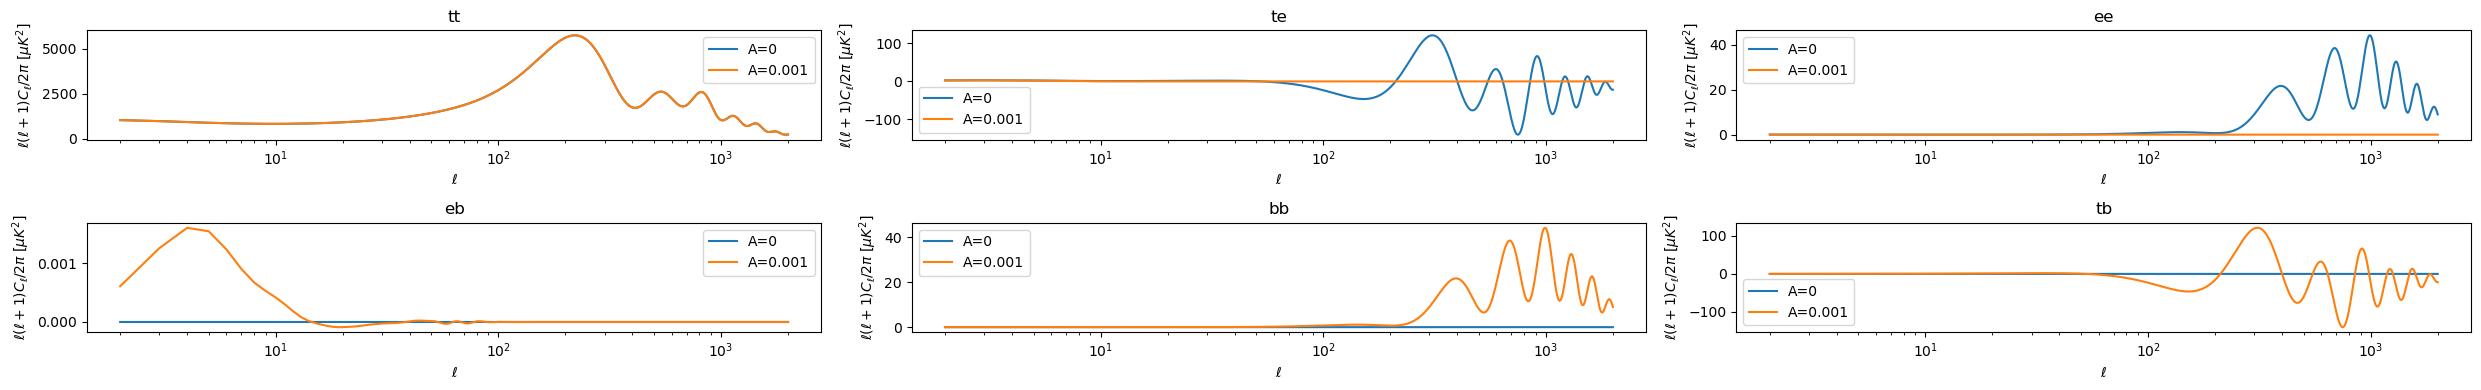

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from classy import Class

# Birefringence angle is hard-coded in class_v3.4.0/source/background.c:
#   alpha = pi/4 for z > z_reio, 0 for z <= z_reio  (a step at the reionization midpoint)
# so no birefringence_A / birefringence_L 
A_VALUES = [0, 1e-3]
LMAX = 2000
T_CMB = 2.7255e6  # uK
SPECTRA = ['tt', 'te', 'ee', 'eb', 'bb', 'tb']

params = {
    'output': 'tCl,pCl',
    'l_max_scalars': LMAX,
    'lensing': 'no',
    'hierarchy': 'tam',
    # 'z_reio': 7.67,   # change where the step occurs
}

#cosmo = Class()
#cosmo.set(params)
#cosmo.compute()
#cl = cosmo.raw_cl(LMAX)
#z_reio = cosmo.get_current_derived_parameters(['z_reio'])['z_reio']
#cosmo.struct_cleanup()
#cosmo.empty()
results_tam = {}

for A in A_VALUES:
    cosmo = Class()
    cosmo.set(params)
    cosmo.set({'birefringence_A': A})
    cosmo.compute()
    cl = cosmo.raw_cl(LMAX)
    z_reio = cosmo.get_current_derived_parameters(['z_reio'])['z_reio']
    results_tam[A] = cl
    cosmo.struct_cleanup()
    cosmo.empty()

ell = cl['ell']
fac = ell * (ell + 1) / (2 * np.pi) * T_CMB**2

#fig, axes = plt.subplots(2, 3, figsize=(18, 8))
#for ax, key in zip(axes.flat, SPECTRA):
#    ax.plot(ell[2:], (fac * cl[key])[2:])
#    ax.set_xlabel(r'$\ell$')
#    ax.set_ylabel(r'$\ell(\ell+1)C_\ell/2\pi\ [\mu K^2]$')
#    ax.set_xscale('log')
#    ax.set_title(key.upper())
#fig.suptitle(rf'$\alpha=\pi/4$ for $z>z_{{reio}}$ ({z_reio:.2f}), $0$ after')
#plt.tight_layout()
#plt.show()

fig, axes = plt.subplots(2, 3, figsize=(25, 4))
for ax, key in zip(axes.flat, SPECTRA): #zip is a function that pairs axes[0],eb and axes[1],bb and axes[2],tb
    for A, cl in results_tam.items(): #results_tam holds all the Cl arrays for different A values, so we loop through them
        y = fac*cl[key]
        ax.plot(ell[2:], y[2:], label=f"A={A:g}")
    ax.set_xscale('log')
    ax.set_title(key)
    ax.set_xlabel(r'$\ell$')
    ax.set_ylabel(r'$\ell(\ell+1)C_\ell/2\pi\ [\mu K^2]$')
    ax.legend()
plt.tight_layout()
plt.show()


/tmp/ipykernel_106780/3919628932.py:9: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0, 30)


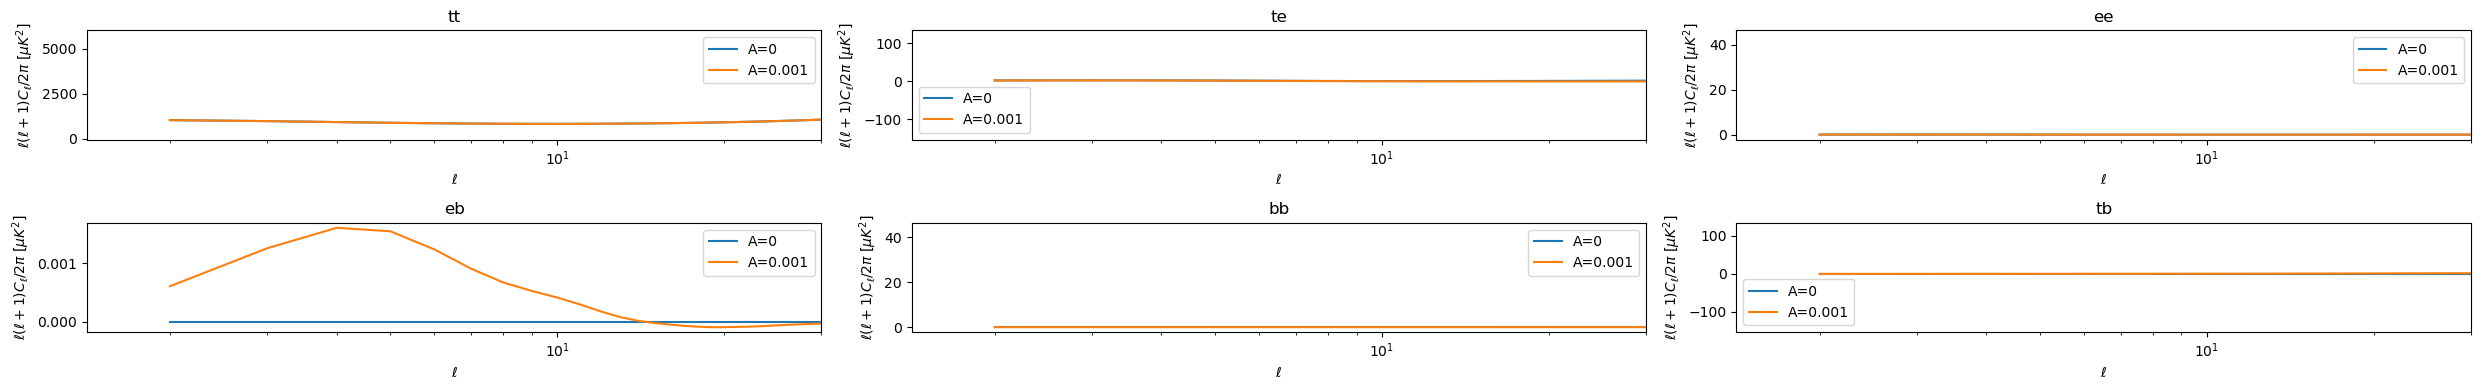

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(25, 4))
for ax, key in zip(axes.flat, SPECTRA): #zip is a function that pairs axes[0],eb and axes[1],bb and axes[2],tb
    for A, cl in results_tam.items(): #results_tam holds all the Cl arrays for different A values, so we loop through them
        y = fac*cl[key]
        ax.plot(ell[2:], y[2:], label=f"A={A:g}")
    ax.set_xscale('log')
    ax.set_title(key)
    ax.set_xlabel(r'$\ell$')
    ax.set_xlim(0, 30)
    ax.set_ylabel(r'$\ell(\ell+1)C_\ell/2\pi\ [\mu K^2]$')
    ax.legend()
plt.tight_layout()
plt.show()